# Proyecto: Campeonato Mundial de F1 - 03. Clustering de pilotos

### Maestria en Inteligencia Artificial Aplicada UCSM - UTPL

### Curso: Herramientas para Inteligencia Artificial

### Github:
https://github.com/vchirinosb/f1-championship

### Plataformas utilizadas:
- Jupyter Lab
- Kaggle (origen del dataset)
- MLflow

### Librerias utilizadas
- pandas==3.1.1
- numpy==2.5.5
- scikit-learn==1.9.1
- bokeh==3.10.2
- playwright==1.65.2
- mlflow==3.18.0
- skops==0.16.0

Agrupamos a los pilotos según su perfil de desempeño a lo largo de su carrera deportiva, igual que el clustering de
juegos del proyecto de Steam. El objetivo es encontrar tipos de piloto interpretables (campeones, ganadores, zona media,
fondo de parrilla) y poder asignar un grupo a cualquier piloto. El modelo elegido se registra en MLflow para que la API
lo use.

## Preparación del entorno

El código compartido está en `src/f1`: `features` (perfil de cada piloto), `plots` (exportación de gráficos) y
`tracking` (registro en MLflow). Antes de ejecutar la última sección, el servidor de MLflow debe estar iniciado (ver
README).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

In [2]:
import numpy as np
import pandas as pd
from bokeh.io import output_notebook
from bokeh.layouts import gridplot
from bokeh.models import ColumnDataSource, HoverTool
from bokeh.plotting import figure
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from f1 import features, plots, tracking
from f1.config import FINAL_DATA_DIR

import mlflow

In [3]:
plots.INTERACTIVE = False
output_notebook(hide_banner=True)
RANDOM_STATE = 42

## Lectura del dataset final

El dataset final del notebook 02 tiene una fila por piloto y carrera (solo pilotos que tomaron la salida), con los
puntos
recalculados con el sistema de 2010 y las marcas de victoria, podio y carrera terminada.

In [4]:
final = pd.read_csv(FINAL_DATA_DIR / "f1_dataset_final.csv")
final.shape

(25146, 39)

## Preparación de los datos

### Perfil de cada piloto

`features.build_driver_profiles` resume la carrera deportiva de cada piloto en una fila. Para que las tasas sean
confiables solo se consideran los pilotos con al menos 20 carreras. Las variables del perfil son:

* **win_rate** / **podium_rate**: proporción de carreras ganadas / terminadas en el podio.
* **dnf_rate**: proporción de carreras que no terminó (*Did Not Finish*).
* **points_per_race**: puntos por carrera con el sistema de 2010 (25-18-15-...), para comparar épocas con sistemas de
  puntos distintos.
* **mean_grid**: posición de salida media, sin contar las salidas desde el pit lane.
* **mean_positions_gained**: posiciones ganadas medias entre la salida y la llegada.
* **seasons**: número de temporadas en las que corrió.

`races`, `first_year` y `last_year` se muestran como referencia, pero no se usan para agrupar.

In [5]:
profiles = features.build_driver_profiles(final)
assert profiles["races"].min() >= features.MIN_RACES
profiles.shape

(251, 13)

In [6]:
profiles.sort_values("win_rate", ascending=False).head(10).round(3)

,driver_id,driver_ref,driver_name,races,first_year,last_year,win_rate,podium_rate,dnf_rate,points_per_race,mean_grid,mean_positions_gained,seasons
202,579,fangio,Juan Fangio,58,1950,1958,0.414,0.603,0.241,15.052,2.483,-2.310,8
209,647,ascari,Alberto Ascari,36,1950,1955,0.361,0.472,0.389,12.306,4.583,-3.861,6
180,373,clark,Jim Clark,73,1960,1968,0.342,0.438,0.397,11.493,3.603,-3.493,9
228,830,max_verstappen,Max Verstappen,209,2015,2024,0.301,0.536,0.153,13.861,4.981,-0.606,10
28,30,michael_schumacher,Michael Schumacher,308,1991,2012,0.295,0.503,0.227,12.630,4.867,-2.013,19
0,1,hamilton,Lewis Hamilton,356,2007,2024,0.295,0.567,0.096,14.480,4.313,-0.696,18
168,328,stewart,Jackie Stewart,99,1965,1973,0.273,0.434,0.384,11.202,4.495,-2.727,9
85,117,prost,Alain Prost,200,1980,1993,0.255,0.530,0.315,12.415,4.126,-3.116,13
77,102,senna,Ayrton Senna,161,1984,1994,0.255,0.497,0.398,11.683,3.149,-4.988,11
194,475,moss,Stirling Moss,72,1951,1961,0.222,0.333,0.486,8.556,5.125,-3.903,11


Quedan 251 pilotos con al menos 20 carreras. Los de mayor tasa de victorias son los grandes campeones: Juan Manuel
Fangio ganó el 41.4 % de sus 58 carreras, seguido de Alberto Ascari (36.1 %) y Jim Clark (34.2 %). Entre los
actuales, Max Verstappen (30.1 %) supera a Michael Schumacher y Lewis Hamilton (29.5 % cada uno); Hamilton tiene la
menor tasa de abandonos del grupo (9.6 %).

**Estadísticas del perfil: cantidad de pilotos, promedio, desviación estándar, mínimo, cuartiles y máximo.**

In [7]:
FEATURES = features.PROFILE_FEATURES
profiles[FEATURES].describe().round(3)

,win_rate,podium_rate,dnf_rate,points_per_race,mean_grid,mean_positions_gained,seasons
count,251.000,251.000,251.000,251.000,251.000,251.000,251.000
mean,0.031,0.098,0.430,3.514,13.286,0.657,7.219
std,0.066,0.135,0.171,3.220,4.831,2.727,4.227
min,0.000,0.000,0.065,0.000,2.483,-6.653,1.000
25%,0.000,0.000,0.303,1.068,9.297,-1.079,4.000
50%,0.000,0.029,0.442,2.333,13.311,0.286,6.000
75%,0.034,0.159,0.556,5.651,17.046,2.167,10.000
max,0.414,0.603,0.818,15.052,24.192,8.500,21.000


### Histogramas

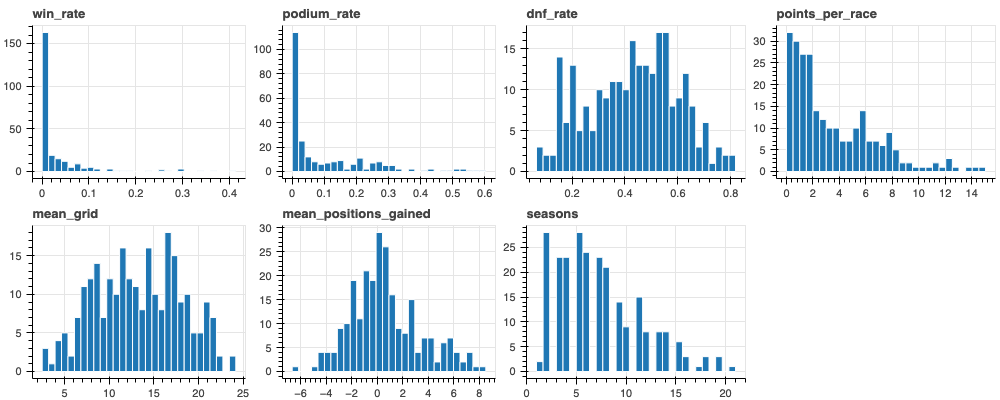

In [8]:
plots.render(
    gridplot(
        [
            plots.create_histogram(profiles[column], column, bins=30)
            for column in FEATURES
        ],
        ncols=4,
    ),
    "hist_driver_profiles",
);

* **win_rate** y **podium_rate** están concentradas en 0: el 59 % de los pilotos nunca ganó y el 37 % nunca subió al
  podio. Solo unos pocos superan el 20 % de victorias.
* **points_per_race** tiene una cola hacia la derecha: mediana de 2.3 puntos y máximo de 15.1 (Fangio).
* **dnf_rate** y **mean_grid** se reparten de forma más simétrica: la mitad de los pilotos abandonó el 44 % de sus
  carreras o más, y sale en promedio del 13.° lugar.
* **mean_positions_gained** es positiva para los pilotos que salen atrás (ganan puestos por los abandonos de otros) y
  negativa para los que salen adelante.
* **seasons** va de 1 a 21 temporadas, con mediana de 6.

### Eliminar outliers

En el perfil no hay valores imposibles: las tasas están entre 0 y 1 y las medias son posiciones reales. Para buscar
pilotos atípicos usamos DBSCAN sobre los datos estandarizados: marca como ruido (`-1`) a los pilotos que no tienen
vecinos cercanos.

In [9]:
scaled = StandardScaler().fit_transform(profiles[FEATURES])
noise = DBSCAN(eps=1.5, min_samples=5).fit_predict(scaled) == -1
profiles.loc[noise, ["driver_name", "races", *FEATURES]].sort_values(
    "win_rate", ascending=False
).round(3)

,driver_name,races,win_rate,podium_rate,dnf_rate,points_per_race,mean_grid,mean_positions_gained,seasons
202,Juan Fangio,58,0.414,0.603,0.241,15.052,2.483,-2.310,8
209,Alberto Ascari,36,0.361,0.472,0.389,12.306,4.583,-3.861,6
180,Jim Clark,73,0.342,0.438,0.397,11.493,3.603,-3.493,9
228,Max Verstappen,209,0.301,0.536,0.153,13.861,4.981,-0.606,10
28,Michael Schumacher,308,0.295,0.503,0.227,12.630,4.867,-2.013,19
0,Lewis Hamilton,356,0.295,0.567,0.096,14.480,4.313,-0.696,18
168,Jackie Stewart,99,0.273,0.434,0.384,11.202,4.495,-2.727,9
85,Alain Prost,200,0.255,0.530,0.315,12.415,4.126,-3.116,13
77,Ayrton Senna,161,0.255,0.497,0.398,11.683,3.149,-4.988,11
19,Sebastian Vettel,300,0.177,0.407,0.153,10.957,6.309,-0.725,16


DBSCAN marca como atípicos a 11 pilotos, y todos son campeones del mundo: Hamilton, Schumacher, Verstappen, Vettel,
Senna, Prost, Stewart, Clark, Fangio, Farina y Ascari. No son errores de los datos sino los pilotos más destacados de la
historia, igual que los grandes éxitos del proyecto de Steam. Por eso **no se elimina ningún piloto**: forman el grupo
de los campeones.

### Escala logarítmica

`seasons` es un conteo: la mayoría de los pilotos corrió pocas temporadas y unos pocos más de 15. Se aplica `log(1 + x)`
para que esos pocos no dominen la distancia. Las demás variables son tasas o medias que ya están en un rango acotado.

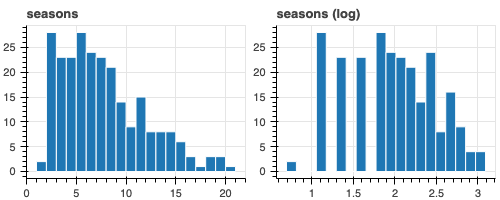

In [10]:
LOG_FEATURES = ["seasons"]
plots.render(
    gridplot(
        [
            plots.create_histogram(profiles["seasons"], "seasons", bins=20),
            plots.create_histogram(
                np.log1p(profiles["seasons"]), "seasons (log)", bins=20)
        ],
        ncols=2,
    ),
    "hist_seasons_log",
);

### Estandarizar

Las variables tienen unidades distintas (tasas, puntos, posiciones, temporadas), así que se estandarizan antes de
agrupar. El logaritmo y la estandarización se guardan en un `Pipeline` de scikit-learn: así se aplican las mismas
transformaciones al clasificar un piloto nuevo y al servir el modelo desde la API.

In [11]:
log = ColumnTransformer(
    [("log", FunctionTransformer(np.log1p), LOG_FEATURES)],
    remainder="passthrough",
)
preprocess = make_pipeline(log, StandardScaler())
X = preprocess.fit_transform(profiles[FEATURES])
X.shape

(251, 7)

## Número de clusters

Ejecutamos K-Means con k de 1 a 10. El **método del codo** grafica la inercia (suma de distancias al centro de cada
grupo)
y se elige k donde la curva se "dobla". El **coeficiente de silueta** mide de -1 a 1 qué tan separado está cada piloto
de los otros grupos; se calcula desde k = 2.

In [12]:
k_values = list(range(1, 11))
kmeans_models = {
    k: KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    for k in k_values
}
inertia = [kmeans_models[k].inertia_ for k in k_values]
silhouette = {
    k: silhouette_score(X, kmeans_models[k].labels_) for k in k_values[1:]
}

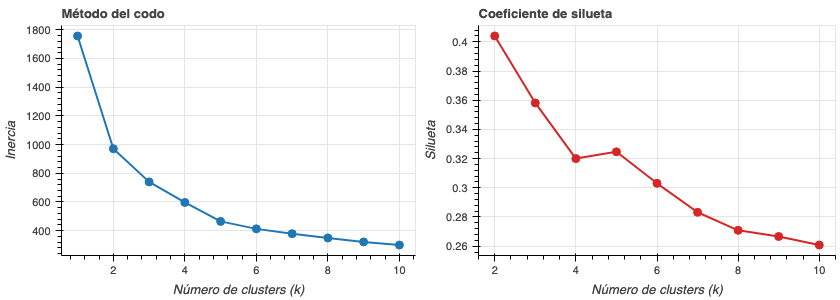

In [13]:
elbow = figure(title="Método del codo", width=420, height=300)
elbow.line(k_values, inertia, line_width=2)
elbow.scatter(k_values, inertia, size=8)
elbow.xaxis.axis_label = "Número de clusters (k)"
elbow.yaxis.axis_label = "Inercia"

silhouette_chart = figure(
    title="Coeficiente de silueta", width=420, height=300)
silhouette_chart.line(
    list(silhouette), list(silhouette.values()), line_width=2,
    color="#d62728"
)
silhouette_chart.scatter(
    list(silhouette), list(silhouette.values()), size=8,
    color="#d62728"
)
silhouette_chart.xaxis.axis_label = "Número de clusters (k)"
silhouette_chart.yaxis.axis_label = "Silueta"
elbow_path = plots.render(
    gridplot([elbow, silhouette_chart], ncols=2),
    "elbow_silhouette"
)

La inercia baja rápido hasta k = 3 y desde k = 5 baja lento. La silueta es máxima con k = 2 (0.404), pero dos grupos
solo separan a los pilotos con victorias de los que no ganaron. Con k = 4 la silueta es 0.320, casi igual a la de k = 5
(0.325), y los grupos coinciden con los cuatro perfiles de la propuesta: campeones, ganadores ocasionales, zona media y
fondo de parrilla.

## Comparación K-Means / jerárquico / GMM

Comparamos tres algoritmos con k de 2 a 8 usando la silueta:

* **K-Means**: asigna cada piloto al centro más cercano; los grupos tienden a ser esféricos y de tamaño parecido.
* **Jerárquico (Ward)**: une pilotos y grupos de abajo hacia arriba, minimizando la varianza dentro de cada grupo.
* **GMM** (*Gaussian Mixture Model*): modela cada grupo como una distribución normal, con forma y tamaño propios.

In [14]:
ALGORITHMS = {
    "kmeans": lambda k: KMeans(
        n_clusters=k, n_init=10, random_state=RANDOM_STATE),
    "ward": lambda k: AgglomerativeClustering(n_clusters=k),
    "gmm": lambda k: GaussianMixture(
        n_components=k, n_init=5, random_state=RANDOM_STATE),
}
comparison = pd.DataFrame(
    [
        {"algorithm": algorithm, "k": k,
         "silhouette": silhouette_score(X, create(k).fit_predict(X))}
        for algorithm, create in ALGORITHMS.items()
        for k in range(2, 9)
    ]
)
comparison.pivot(index="k", columns="algorithm", values="silhouette")[
    list(ALGORITHMS)
].round(3)

algorithm,kmeans,ward,gmm
k,,,
2,0.404,0.399,0.346
3,0.358,0.374,0.247
4,0.320,0.297,0.123
5,0.325,0.284,0.205
6,0.303,0.255,0.110
7,0.283,0.237,0.084
8,0.271,0.221,0.053


K-Means tiene la mejor silueta en casi todos los k: con k = 4 obtiene 0.320, frente a 0.297 del jerárquico y 0.123 de
GMM. El jerárquico solo es mejor con k = 3 (0.374 frente a 0.358). GMM queda último en todos los casos: con solo 251
pilotos y 7 variables, estimar una distribución con forma propia para cada grupo es inestable. **Elegimos K-Means con
k = 4**, por su silueta y porque, como en el proyecto de Steam, asigna un piloto nuevo al centro más cercano.

## K-Means con 4 grupos

El modelo final es un `Pipeline` con el preprocesamiento y K-Means. Es el que se registra en MLflow.

In [15]:
K = 4
model = make_pipeline(
    preprocess,
    KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE),
)
profiles["cluster"] = model.fit_predict(profiles[FEATURES])

K-Means numera los grupos al azar. Les ponemos nombre según su posición de salida mediana, de la peor a la mejor:
**BACKMARKER** (fondo de parrilla), **MIDFIELD** (zona media), **WINNER** (ganadores ocasionales) y **CHAMPION**
(campeones).

In [16]:
GROUPS = ["BACKMARKER", "MIDFIELD", "WINNER", "CHAMPION"]
COLORS = ["#7f7f7f", "#2ca02c", "#1f77b4", "#d62728"]
order = (
    profiles.groupby("cluster")["mean_grid"]
    .median()
    .sort_values(ascending=False)
    .index
)
# Nombre de cada grupo, en el orden del número de grupo
group_names = pd.Series(GROUPS, index=order).sort_index().tolist()
profiles["group"] = profiles["cluster"].map(dict(enumerate(group_names)))

**Cantidad de pilotos en cada grupo**

In [17]:
group_count = profiles["group"].value_counts().reindex(GROUPS)
group_count

group
BACKMARKER    91
MIDFIELD      52
WINNER        93
CHAMPION      15
Name: count, dtype: int64

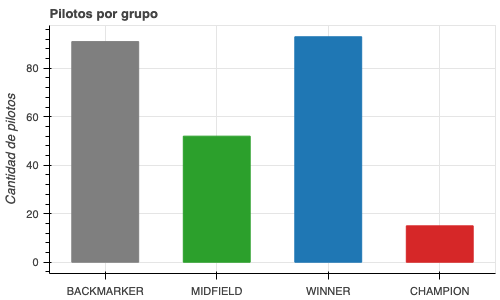

In [18]:
chart = figure(
    x_range=GROUPS, title="Pilotos por grupo", width=500, height=300)
chart.vbar(x=GROUPS, top=group_count.tolist(), width=0.6, color=COLORS)
chart.yaxis.axis_label = "Cantidad de pilotos"
plots.render(chart, "drivers_per_group");

## Gráficos de los grupos

Una función dibuja dos columnas con un color por grupo y una estrella en la mediana de cada grupo. En modo interactivo,
al pasar el cursor se ve el nombre del piloto.

In [19]:
def plot_scatter(frame, x_column, y_column, name, title=None):
    """
    Dibujar dos columnas con un color por grupo y su mediana.

    :param frame: Pilotos con las columnas a graficar y 'group'.
    :param x_column: Columna del eje x.
    :param y_column: columna del eje y.
    :param name: nombre del PNG en images/.
    :param title: Título del gráfico; por defecto, 'x vs y'.

    :return: Ruta del PNG generado.
    """
    chart = figure(
        title=title or f"{x_column} vs {y_column}", width=800, height=450)
    for group, color in zip(GROUPS, COLORS):
        subset = frame[frame["group"] == group]
        source = ColumnDataSource(
            {
                "x": subset[x_column],
                "y": subset[y_column],
                "driver": subset["driver_name"]
            }
        )
        chart.scatter(
            "x", "y", source=source, size=6, alpha=0.5, color=color,
            legend_label=group
        )
        chart.scatter(
            [subset[x_column].median()],
            [subset[y_column].median()], marker="star", size=22,
            color=color, line_color="black"
        )
    chart.add_tools(HoverTool(tooltips=[("Piloto", "@driver")]))
    chart.xaxis.axis_label = x_column
    chart.yaxis.axis_label = y_column
    chart.legend.location = "top_right"

    return plots.render(chart, name)

**Componentes principales (PCA).** Las 7 variables se reducen a 2 componentes para ver los grupos en un plano.

In [20]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
components = pca.fit_transform(model[:-1].transform(profiles[FEATURES]))
profiles["pc1"], profiles["pc2"] = components.T
pca.explained_variance_ratio_.round(3)

array([0.643, 0.141])

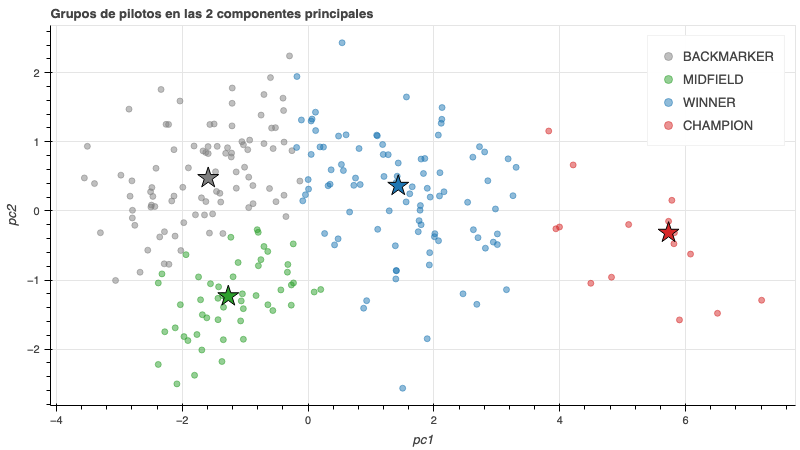

In [21]:
pca_path = plot_scatter(
    profiles, "pc1", "pc2", "clusters_pca",
    "Grupos de pilotos en las 2 componentes principales"
)

Las dos componentes explican el 78.4 % de la varianza (64.3 % y 14.1 %). La primera ordena a los pilotos por su
rendimiento: a la izquierda el fondo de parrilla y la zona media, a la derecha los ganadores y, separados del resto,
los 15 campeones. La segunda separa la zona media (abajo) del fondo de parrilla (arriba), que tienen un rendimiento
parecido pero distinta tasa de abandonos.

**Tasa de abandonos vs temporadas.**

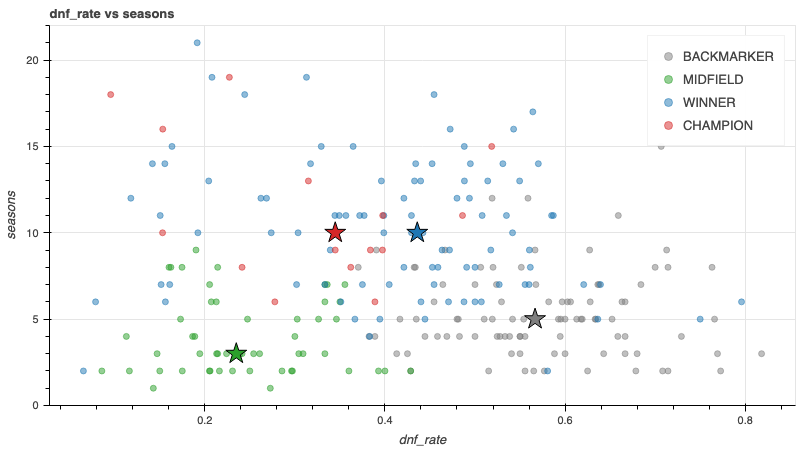

In [22]:
plot_scatter(profiles, "dnf_rate", "seasons", "clusters_dnf_seasons");

El gráfico muestra la diferencia entre fondo de parrilla y zona media: los dos casi no suman puntos, pero el fondo de
parrilla abandona más de la mitad de las carreras y la zona media, en mediana, menos de una de cada cuatro. Los
campeones y los ganadores tienen las carreras más largas: la mitad corrió 10 temporadas o más.

## Estadísticas de cada grupo

Estadísticas en base a la mediana.

In [23]:
summary = profiles.groupby("group")[
    ["races", "first_year", *FEATURES]
].median()
summary = summary.reindex(GROUPS)
summary["drivers"] = group_count
summary.round(3)

,races,first_year,win_rate,podium_rate,dnf_rate,points_per_race,mean_grid,mean_positions_gained,seasons,drivers
group,,,,,,,,,,
BACKMARKER,41.0,1984.0,0.000,0.000,0.567,1.364,17.317,2.706,5.0,91
MIDFIELD,46.0,2011.0,0.000,0.000,0.235,0.753,15.171,0.850,3.0,52
WINNER,116.0,1975.0,0.034,0.163,0.436,5.769,9.122,-1.060,10.0,93
CHAMPION,116.0,1980.0,0.255,0.497,0.345,11.683,4.583,-2.727,10.0,15


**Los 10 pilotos con más puntos por carrera de cada grupo**

In [24]:
top_drivers = pd.DataFrame(
    {
        group: profiles[profiles["group"] == group]
        .nlargest(10, "points_per_race")["driver_name"]
        .values
        for group in GROUPS
    }
)
top_drivers

,BACKMARKER,MIDFIELD,WINNER,CHAMPION
0,Stefan Johansson,Tony Maggs,Mike Hawthorn,Juan Fangio
1,Toulo de Graffenried,Louis Rosier,Charles Leclerc,Lewis Hamilton
2,Jochen Mass,Alexander Wurz,Juan Pablo Montoya,Max Verstappen
3,Martin Brundle,Esteban Ocon,Mika Häkkinen,Michael Schumacher
4,Tom Pryce,Pierre Gasly,Nico Rosberg,Nino Farina
5,Piers Courage,Heikki Kovalainen,Denny Hulme,Alain Prost
6,Mark Blundell,Alexander Albon,Wolfgang von Trips,Alberto Ascari
7,Giancarlo Baghetti,Paul di Resta,Nelson Piquet,Ayrton Senna
8,Bob Anderson,Carel Godin de Beaufort,Jody Scheckter,Jim Clark
9,Eddie Cheever,Daniil Kvyat,Richie Ginther,Jackie Stewart


In [25]:
champions = profiles.loc[profiles["group"] == "CHAMPION", "driver_name"]
assert {"Lewis Hamilton", "Michael Schumacher"} <= set(champions)
champions.tolist()

['Lewis Hamilton',
 'Sebastian Vettel',
 'Michael Schumacher',
 'Damon Hill',
 'Nigel Mansell',
 'Ayrton Senna',
 'Alain Prost',
 'Jackie Stewart',
 'Jim Clark',
 'Stirling Moss',
 'José Froilán González',
 'Juan Fangio',
 'Nino Farina',
 'Alberto Ascari',
 'Max Verstappen']

Según las estadísticas:

- **CHAMPION** (rojo) es el grupo más pequeño: 15 pilotos (6 %), entre ellos 13 campeones del mundo. Ganan una de cada
  cuatro carreras, suben al podio en la mitad, salen en promedio 4.6.° y suman 11.7 puntos por carrera. Incluye a Lewis
  Hamilton y Michael Schumacher, como pide la verificación.

- **WINNER** (azul) tiene 93 pilotos (37 %): ganadores ocasionales y pilotos de equipos competitivos, como Häkkinen,
  Rosberg, Piquet o Leclerc. Mediana de 3.4 % de victorias, 16.3 % de podios, salida 9.1.° y carreras largas (10
  temporadas).

- **MIDFIELD** (verde) tiene 52 pilotos (21 %). Casi no suman puntos (0.75 por carrera), pero abandonan poco (23.5 %) y
  salen 15.2.°. Son sobre todo pilotos de los años 2000 en adelante (mediana de debut: 2011), como Ocon, Gasly o Albon:
  con coches más fiables terminan las carreras, pero lejos de los puntos.

- **BACKMARKER** (gris) tiene 91 pilotos (36 %). Salen al fondo (17.3.°) y abandonan más de la mitad de las carreras
  (56.7 %). Son en su mayoría pilotos de los años 70 a 90 (mediana de debut: 1984), cuando los abandonos eran más
  comunes; por eso suman algo más de puntos que la zona media: con menos coches en carrera era más fácil terminar en los
  puntos.

La diferencia entre zona media y fondo de parrilla muestra que el perfil también refleja la época: la tasa de abandonos
bajó mucho con la fiabilidad de los coches modernos.

## Clasificar un piloto nuevo

El `Pipeline` aplica al perfil nuevo el mismo logaritmo y la misma estandarización, y K-Means le asigna el grupo más
cercano.

In [26]:
def classify_driver(profile, pipeline=model, names=group_names):
    """
    Asignar un grupo al perfil de un piloto.

    :param profile: Diccionario con las variables de FEATURES.
    :param pipeline: Modelo de clustering; por defecto, el entrenado aquí.
    :param names: Nombre de cada grupo, indexado por número de grupo.

    :return: Nombre del grupo.
    """
    cluster = pipeline.predict(pd.DataFrame([profile])[FEATURES])[0]
    return names[cluster]

In [27]:
# CHAMPION: gana una de cada cuatro carreras y sale casi siempre adelante.
classify_driver(
    {
        "win_rate": 0.25, "podium_rate": 0.55, "dnf_rate": 0.15,
        "points_per_race": 13.0, "mean_grid": 3.5,
        "mean_positions_gained": -1.0, "seasons": 10
    }
)

'CHAMPION'

In [28]:
# WINNER: algunas victorias y podios frecuentes en un equipo competitivo.
classify_driver(
    {
        "win_rate": 0.03, "podium_rate": 0.15, "dnf_rate": 0.25,
        "points_per_race": 6.0, "mean_grid": 8.0,
        "mean_positions_gained": -0.5, "seasons": 9
    }
)

'WINNER'

In [29]:
# BACKMARKER: sale al fondo y abandona más de la mitad de las carreras.
classify_driver(
    {
        "win_rate": 0.0, "podium_rate": 0.0, "dnf_rate": 0.6,
        "points_per_race": 0.5, "mean_grid": 19.0,
        "mean_positions_gained": 3.0, "seasons": 3
    }
)

'BACKMARKER'

## Registro en MLflow

Igual que en la referencia de clase06, la comparación se registra como una ejecución padre con una ejecución hija por
algoritmo y k. El modelo elegido se guarda en la ejecución padre con sus métricas, los gráficos del codo y del PCA, y el
nombre de cada grupo como metadato. Luego se registra como `f1-driver-clustering` con el alias `champion`, que es la
versión que carga la API.

In [30]:
final_silhouette = silhouette_score(X, profiles["cluster"])
with tracking.start_run(tracking.CLUSTERING_EXPERIMENT, "driver_profiles"):
    for row in comparison.itertuples():
        with tracking.start_run(
            run_name=f"{row.algorithm}_k{row.k}", nested=True
        ):
            mlflow.log_params({"algorithm": row.algorithm, "k": row.k})
            mlflow.log_metric("silhouette", row.silhouette)

    mlflow.log_params(
        {
            "algorithm": "kmeans", "k": K, "min_races": features.MIN_RACES,
            "features": ", ".join(FEATURES), "log_features": "seasons",
            "drivers": len(profiles)
        }
    )
    mlflow.log_metrics(
        {"silhouette": final_silhouette, "inertia": model[-1].inertia_}
    )
    mlflow.log_artifact(elbow_path)
    mlflow.log_artifact(pca_path)
    info = tracking.log_model(
        model, profiles[FEATURES],
        {"group_names": group_names}
    )

version = tracking.register_champion(
    info.model_uri, tracking.CLUSTERING_MODEL)
version, round(final_silhouette, 3)

Registered model 'f1-driver-clustering' already exists. Creating a new version of this model...
Created version '3' of model 'f1-driver-clustering'.


(3, 0.32)

**Verificación:** cargamos el modelo `champion` desde MLflow, como lo hará la API, y clasificamos un perfil nuevo con la
misma función `classify_driver`.

In [31]:
uri = f"models:/{tracking.CLUSTERING_MODEL}@{tracking.CHAMPION_ALIAS}"
champion = tracking.load_champion(tracking.CLUSTERING_MODEL)
champion_names = mlflow.models.get_model_info(uri).metadata["group_names"]
classify_driver(
    {
        "win_rate": 0.3, "podium_rate": 0.6, "dnf_rate": 0.1,
        "points_per_race": 14.0, "mean_grid": 2.5,
        "mean_positions_gained": -1.5, "seasons": 8
    },
    champion,
    champion_names,
)

'CHAMPION'

En el experimento `f1-clustering` quedan una ejecución padre (`driver_profiles`) y 21 ejecuciones hijas, una por
algoritmo y k, que se pueden comparar por silueta en la interfaz de MLflow. El `Pipeline` quedó registrado como una
nueva versión de `f1-driver-clustering` (la 3 en esta ejecución) con el alias `champion`. Al cargarlo desde MLflow, el
perfil nuevo (30 % de victorias, salida 2.5.°) se clasifica como **CHAMPION**, con los nombres de grupo leídos de los
metadatos del modelo.

## Conclusiones

- Con el dataset final construimos el perfil de 251 pilotos con al menos 20 carreras: tasas de victorias, podios y
  abandonos, puntos por carrera con el sistema de 2010, posición de salida media, posiciones ganadas y temporadas.
- DBSCAN marcó como atípicos a 11 campeones del mundo; no se eliminaron porque son el grupo de los campeones. Se aplicó
  logaritmo a las temporadas y se estandarizaron las variables dentro de un `Pipeline`.
- Comparamos K-Means, jerárquico (Ward) y GMM con k de 2 a 8. Elegimos K-Means con 4 grupos (silueta 0.320) por su
  silueta y porque los grupos son interpretables: **CHAMPION**, **WINNER**, **MIDFIELD** y **BACKMARKER**.
- El grupo de campeones reúne a Fangio, Hamilton, Schumacher, Verstappen, Senna y Prost, entre otros. La separación
  entre zona media y fondo de parrilla refleja también la época: los pilotos modernos abandonan mucho menos.
- Con el `Pipeline` se clasifica cualquier piloto nuevo, y el modelo quedó registrado en MLflow como
  `f1-driver-clustering@champion` para que la API asigne el grupo de un piloto.